### Setup

In [1]:
import os
os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")
from pathlib import Path

project_folder = "/Users/md_halim_mondol/Desktop/STEPS-LLM/VLM/DSPy_project"
os.chdir(project_folder)
print("Current directory:", os.getcwd())

import dspy
lm = dspy.LM("openai/gpt-4o-mini")
dspy.configure(lm=lm, track_usage=False)

Current directory: /Users/md_halim_mondol/Desktop/STEPS-LLM/VLM/DSPy_project


### PDF Text Extraction

In [2]:
import pdfplumber

def extract_text_from_pdf(path):
    text = ""
    with pdfplumber.open(path) as pdf:
        for page in pdf.pages:
            text += page.extract_text() + "\n"
    return text

### DSPy Signature and Module

In [3]:
class ExtractTable(dspy.Signature):
    report_text = dspy.InputField(
        desc="Full text of a scientific report. The report may contain multiple tables."
    )
    table = dspy.OutputField(
        desc=(
            "Extract only the main raw data table from the report, not any summary table. "
            "Return the table exactly as plain text with the original column names, row order, "
            "numerical values, and units. Do not summarize, do not compute statistics, "
            "and do not output markdown."
        )
    )

In [4]:
class TableExtractor(dspy.Module):
    def __init__(self):
        super().__init__()
        self.extract = dspy.ChainOfThought(ExtractTable)

    def forward(self, report_text):
        return self.extract(report_text=report_text)

### Metric

In [5]:
import re

def normalize_table_text(text: str) -> str:
    lines = []
    for line in text.strip().splitlines():
        line = " ".join(line.strip().split())
        if line:
            lines.append(line)
    return "\n".join(lines)

def split_lines(text: str):
    return [line for line in normalize_table_text(text).splitlines() if line.strip()]

def numeric_tokens(text: str):
    return re.findall(r"-?\d+(?:\.\d+)?", text)

def token_overlap_ratio(seq1, seq2):
    if not seq1:
        return 0.0
    matched = sum(1 for a, b in zip(seq1, seq2) if a == b)
    return matched / len(seq1)

def table_fractional_metric(example, pred, trace=None):
    gold_text = normalize_table_text(example.table)
    pred_text = normalize_table_text(pred.table)

    gold_lines = split_lines(gold_text)
    pred_lines = split_lines(pred_text)

    gold_header = gold_lines[0] if gold_lines else ""
    pred_header = pred_lines[0] if pred_lines else ""

    gold_rows = gold_lines[1:] if len(gold_lines) > 1 else []
    pred_rows = pred_lines[1:] if len(pred_lines) > 1 else []

    gold_nums = numeric_tokens(gold_text)
    pred_nums = numeric_tokens(pred_text)

    # 1) header preservation: generic, no schema assumptions
    header_score = 1.0 if gold_header == pred_header else 0.0

    # 2) row-count closeness
    if len(gold_rows) == 0:
        row_score = 0.0
    else:
        row_score = max(0.0, 1.0 - abs(len(gold_rows) - len(pred_rows)) / len(gold_rows))

    # 3) numeric preservation in sequence order
    numeric_score = token_overlap_ratio(gold_nums, pred_nums)

    # 4) output is non-empty and table-like
    table_like_score = 1.0 if len(pred_lines) >= 2 and len(pred_nums) > 0 else 0.0

    # 5) exact match bonus
    exact_score = 1.0 if gold_text == pred_text else 0.0

    score = (
        0.15 * table_like_score +
        0.20 * header_score +
        0.20 * row_score +
        0.35 * numeric_score +
        0.10 * exact_score
    )

    # stricter acceptance during bootstrapping
    if trace is not None:
        return score >= 0.75

    return score

### Data Preparation

In [6]:
data_dir = Path("data")
gold_dir = Path("gold_tables")

pdf_files = sorted(data_dir.glob("*.pdf"))

def load_text(path):
    with open(path, "r", encoding="utf-8") as f:
        return f.read().strip()

dataset = []

for pdf_path in pdf_files:
    stem = pdf_path.stem
    gold_path = gold_dir / f"{stem}_table2.txt"

    report_text = extract_text_from_pdf(str(pdf_path))
    gold_table = load_text(gold_path)

    ex = dspy.Example(
        report_text=report_text,
        table=gold_table,
        paper_id=stem
    ).with_inputs("report_text")

    dataset.append(ex)

print("Total examples:", len(dataset))

Total examples: 10


In [7]:
train_examples = dataset[:8]
dev_examples = dataset[8:]

print("Train examples:", len(train_examples))
print("Dev examples:", len(dev_examples))

Train examples: 8
Dev examples: 2


### Evaluation Utilities

In [8]:
def evaluate_model(model, dataset, metric):
    scores = []

    for ex in dataset:
        pred = model(report_text=ex.report_text)
        score = metric(ex, pred)
        scores.append(score)

    avg_score = sum(scores) / len(scores) if scores else 0.0
    return avg_score, scores

In [9]:
def print_scores(name, scores, avg_score):
    print(f"\n{name}")
    print("-" * len(name))

    for i, score in enumerate(scores, start=1):
        print(f"Example {i}: {score:.4f}")

    print(f"\nAverage: {avg_score:.4f}")

### Baseline Extractor

In [10]:
baseline_extractor = TableExtractor()

baseline_dev_avg, baseline_dev_scores = evaluate_model( baseline_extractor, dev_examples, table_fractional_metric )

print_scores("Baseline Dev Scores", baseline_dev_scores, baseline_dev_avg)


Baseline Dev Scores
-------------------
Example 1: 0.4038
Example 2: 0.3375

Average: 0.3706


### BootstrapFewShot Extractor

In [11]:
from dspy.teleprompt import BootstrapFewShot

bootstrap_optimizer = BootstrapFewShot( metric=table_fractional_metric, max_bootstrapped_demos=4, max_labeled_demos=4, max_rounds=1 )

bootstrap_extractor = bootstrap_optimizer.compile( TableExtractor(), trainset=train_examples )

print("BootstrapFewShot compilation done.")

 88%|████████▊ | 7/8 [00:00<00:00, 56.38it/s]

Bootstrapped 4 full traces after 7 examples for up to 1 rounds, amounting to 7 attempts.
BootstrapFewShot compilation done.


In [12]:
bootstrap_dev_avg, bootstrap_dev_scores = evaluate_model( bootstrap_extractor, dev_examples, table_fractional_metric )

print_scores("BootstrapFewShot Dev Scores", bootstrap_dev_scores, bootstrap_dev_avg)


BootstrapFewShot Dev Scores
---------------------------
Example 1: 0.6038
Example 2: 0.5631

Average: 0.5835


### MIPROv2 Extractor

In [13]:
from dspy.teleprompt import MIPROv2

mipro_optimizer = MIPROv2( metric=table_fractional_metric, auto="light", num_threads=1 )

mipro_extractor = mipro_optimizer.compile( TableExtractor(), trainset=train_examples, valset=dev_examples )

print("MIPROv2 compilation done.")

2026/04/28 12:17:23 INFO dspy.teleprompt.mipro_optimizer_v2: 
RUNNING WITH THE FOLLOWING LIGHT AUTO RUN SETTINGS:
num_trials: 10
minibatch: False
num_fewshot_candidates: 6
num_instruct_candidates: 3
valset size: 2

2026/04/28 12:17:23 INFO dspy.teleprompt.mipro_optimizer_v2: 
==> STEP 1: BOOTSTRAP FEWSHOT EXAMPLES <==
2026/04/28 12:17:23 INFO dspy.teleprompt.mipro_optimizer_v2: These will be used as few-shot example candidates for our program and for creating instructions.

2026/04/28 12:17:23 INFO dspy.teleprompt.mipro_optimizer_v2: Bootstrapping N=6 sets of demonstrations...


Bootstrapping set 1/6
Bootstrapping set 2/6
Bootstrapping set 3/6


 88%|████████▊ | 7/8 [00:00<00:00, 57.09it/s]


Bootstrapped 4 full traces after 7 examples for up to 1 rounds, amounting to 7 attempts.
Bootstrapping set 4/6


 25%|██▌       | 2/8 [00:00<00:00, 56.15it/s]


Bootstrapped 1 full traces after 2 examples for up to 1 rounds, amounting to 2 attempts.
Bootstrapping set 5/6


... (24 outputs left out)

2026/04/28 12:17:23 INFO dspy.evaluate.evaluate: Average Metric: 0.9238712579484336 / 2 (46.2%)
2026/04/28 12:17:23 INFO dspy.teleprompt.mipro_optimizer_v2: Score: 46.19 with parameters ['Predictor 0: Instruction 2', 'Predictor 0: Few-Shot Set 5'].
2026/04/28 12:17:23 INFO dspy.teleprompt.mipro_optimizer_v2: Scores so far: [37.06, 46.19, 37.06, 46.19, 58.35, 46.19, 37.06, 46.19, 58.35, 46.19]
2026/04/28 12:17:23 INFO dspy.teleprompt.mipro_optimizer_v2: Best score so far: 58.35
2026/04/28 12:17:23 INFO dspy.teleprompt.mipro_optimizer_v2: =========================


2026/04/28 12:17:23 INFO dspy.teleprompt.mipro_optimizer_v2: ===== Trial 11 / 10 =====



Average Metric: 1.17 / 2 (58.3%): 100%|██████████| 2/2 [00:00<00:00, 187.00it/s]

2026/04/28 12:17:23 INFO dspy.evaluate.evaluate: Average Metric: 1.1669040448336796 / 2 (58.3%)
2026/04/28 12:17:23 INFO dspy.teleprompt.mipro_optimizer_v2: Score: 58.35 with parameters ['Predictor 0: Instruction 2', 'Predictor 0: Few-Shot Set 2'].
2026/04/28 12:17:23 INFO dspy.teleprompt.mipro_optimizer_v2: Scores so far: [37.06, 46.19, 37.06, 46.19, 58.35, 46.19, 37.06, 46.19, 58.35, 46.19, 58.35]
2026/04/28 12:17:23 INFO dspy.teleprompt.mipro_optimizer_v2: Best score so far: 58.35
2026/04/28 12:17:23 INFO dspy.teleprompt.mipro_optimizer_v2: =========================


2026/04/28 12:17:23 INFO dspy.teleprompt.mipro_optimizer_v2: Returning best identified program with score 58.35!



MIPROv2 compilation done.


In [14]:
mipro_dev_avg, mipro_dev_scores = evaluate_model( mipro_extractor, dev_examples, table_fractional_metric )

print_scores("MIPROv2 Dev Scores", mipro_dev_scores, mipro_dev_avg)


MIPROv2 Dev Scores
------------------
Example 1: 0.6038
Example 2: 0.5631

Average: 0.5835


### MIPROv2 Optimization Curve

In [15]:
# Check what optimization logs are available
print(type(mipro_extractor))
print(hasattr(mipro_extractor, "score"))
print(hasattr(mipro_extractor, "trial_logs"))
print(hasattr(mipro_optimizer, "trial_logs"))

<class '__main__.TableExtractor'>
True
True
False


In [16]:
# Try to collect MIPRO trial logs
mipro_trial_logs = None

if hasattr(mipro_extractor, "trial_logs"):
    mipro_trial_logs = mipro_extractor.trial_logs
elif hasattr(mipro_optimizer, "trial_logs"):
    mipro_trial_logs = mipro_optimizer.trial_logs

print("Trial logs type:", type(mipro_trial_logs))

if mipro_trial_logs is not None:
    print(mipro_trial_logs)

Trial logs type: <class 'dict'>
{1: {'full_eval_program_path': None, 'full_eval_score': 37.06, 'total_eval_calls_so_far': 2, 'full_eval_program': extract.predict = Predict(StringSignature(report_text -> reasoning, table
    instructions='Given the fields `report_text`, produce the fields `table`.'
    report_text = Field(annotation=str required=True json_schema_extra={'desc': 'Full text of a scientific report. The report may contain multiple tables.', '__dspy_field_type': 'input', 'prefix': 'Report Text:'})
    reasoning = Field(annotation=str required=True json_schema_extra={'prefix': "Reasoning: Let's think step by step in order to", 'desc': '${reasoning}', '__dspy_field_type': 'output'})
    table = Field(annotation=str required=True json_schema_extra={'desc': 'Extract only the main raw data table from the report, not any summary table. Return the table exactly as plain text with the original column names, row order, numerical values, and units. Do not summarize, do not compute stat

Trial steps: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Trial scores: [0.37060000000000004, 0.4619, 0.37060000000000004, 0.4619, 0.5835, 0.4619, 0.37060000000000004, 0.4619, 0.5835, 0.4619, 0.5835]


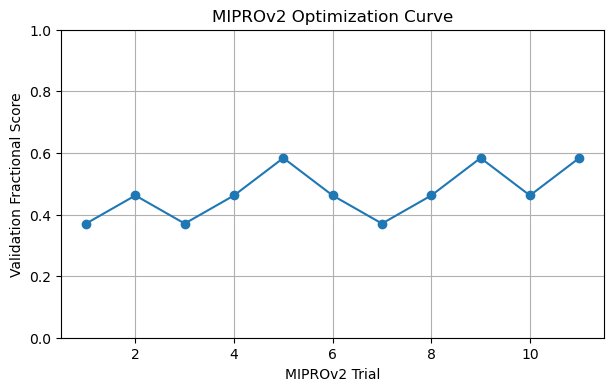

In [36]:
import matplotlib.pyplot as plt

def normalize_score(score):
    score = float(score)
    if score > 1:
        score = score / 100
    return score

trial_steps = []
trial_scores = []

if isinstance(mipro_trial_logs, dict):
    for trial, info in mipro_trial_logs.items():
        trial_steps.append(int(trial))

        if isinstance(info, dict):
            score = info.get("score", None)
            if score is None:
                score = info.get("full_eval_score", None)
            if score is None:
                score = info.get("val_score", None)
        else:
            score = None

        if score is not None:
            trial_scores.append(normalize_score(score))

elif isinstance(mipro_trial_logs, list):
    for i, info in enumerate(mipro_trial_logs):
        trial_steps.append(i)

        if isinstance(info, dict):
            score = info.get("score", None)
            if score is None:
                score = info.get("full_eval_score", None)
            if score is None:
                score = info.get("val_score", None)
        else:
            score = None

        if score is not None:
            trial_scores.append(normalize_score(score))

print("Trial steps:", trial_steps)
print("Trial scores:", trial_scores)

plt.figure(figsize=(7, 4))
plt.plot(trial_steps[:len(trial_scores)], trial_scores, marker="o")
plt.xlabel("MIPROv2 Trial")
plt.ylabel("Validation Fractional Score")
plt.title("MIPROv2 Optimization Curve")
plt.grid(True)
plt.ylim(0, 1)
plt.show()

### Comparison Table

In [18]:
import pandas as pd

comparison_df = pd.DataFrame({ "Model": [ "Baseline", "BootstrapFewShot", "MIPROv2" ], "Dev Average Score": [ baseline_dev_avg, bootstrap_dev_avg, mipro_dev_avg ] })

comparison_df

,Model,Dev Average Score
0,Baseline,0.370647
1,BootstrapFewShot,0.583452
2,MIPROv2,0.583452


### Comparison Bar Plot

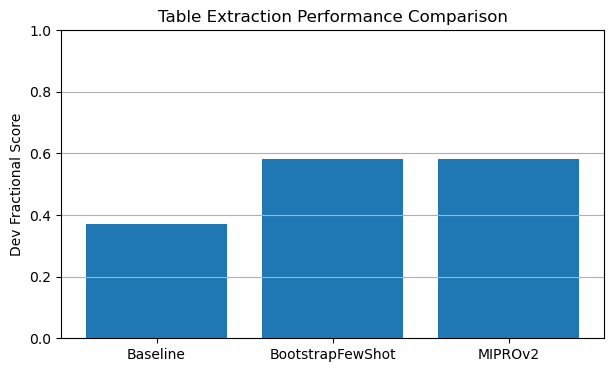

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.bar(comparison_df["Model"], comparison_df["Dev Average Score"])
plt.ylabel("Dev Fractional Score")
plt.title("Table Extraction Performance Comparison")
plt.ylim(0, 1)
plt.grid(axis="y")
plt.show()

### Bootstrap Prompt Improvement Curve

In [20]:
import copy
import matplotlib.pyplot as plt

def get_demo_predictor_and_demos(model):
    for name, pred in model.named_predictors():
        if hasattr(pred, "demos"):
            return name, pred.demos
    raise ValueError("No predictor with demos found.")

demo_predictor_name, bootstrap_demos = get_demo_predictor_and_demos(bootstrap_extractor)

print("Bootstrap demo predictor:", demo_predictor_name)
print("Number of Bootstrap demos:", len(bootstrap_demos))

Bootstrap demo predictor: extract.predict
Number of Bootstrap demos: 4


In [ ]:
bootstrap_curve_steps = [0]
bootstrap_curve_scores = [baseline_dev_avg]

for k in range(1, len(bootstrap_demos) + 1):
    model_k = copy.deepcopy(bootstrap_extractor)

    for name, pred in model_k.named_predictors():
        if name == demo_predictor_name:
            pred.demos = bootstrap_demos[:k]

    score_k, _ = evaluate_model( model_k, dev_examples, table_fractional_metric )

    bootstrap_curve_steps.append(k)
    bootstrap_curve_scores.append(score_k)

    print(f"Step {k}: demos={k}, dev_score={score_k:.4f}")

Step 1: demos=1, dev_score=0.5835
Step 2: demos=2, dev_score=0.5835
Step 3: demos=3, dev_score=0.5835
Step 4: demos=4, dev_score=0.5835


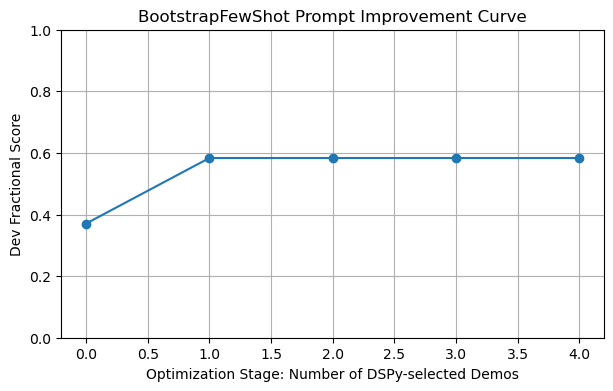

In [22]:
plt.figure(figsize=(7, 4))
plt.plot(bootstrap_curve_steps, bootstrap_curve_scores, marker="o")
plt.xlabel("Optimization Stage: Number of DSPy-selected Demos")
plt.ylabel("Dev Fractional Score")
plt.title("BootstrapFewShot Prompt Improvement Curve")
plt.grid(True)
plt.ylim(0, 1)
plt.show()

### Side-by-Side Output Viewer

In [23]:
from IPython.display import display, HTML
import html

def show_side_by_side(gold, baseline, bootstrap, mipro, title=""):
    gold = html.escape(gold)
    baseline = html.escape(baseline)
    bootstrap = html.escape(bootstrap)
    mipro = html.escape(mipro)

    html_text = f"""
    <h2>{title}</h2>
    <div style="display:flex; gap:15px;">
        <div style="width:25%;">
            <h3>Gold</h3>
            <pre style="white-space: pre-wrap; border:1px solid #ccc; padding:10px; max-height:600px; overflow:auto;">{gold}</pre>
        </div>
        <div style="width:25%;">
            <h3>Baseline</h3>
            <pre style="white-space: pre-wrap; border:1px solid #ccc; padding:10px; max-height:600px; overflow:auto;">{baseline}</pre>
        </div>
        <div style="width:25%;">
            <h3>BootstrapFewShot</h3>
            <pre style="white-space: pre-wrap; border:1px solid #ccc; padding:10px; max-height:600px; overflow:auto;">{bootstrap}</pre>
        </div>
        <div style="width:25%;">
            <h3>MIPROv2</h3>
            <pre style="white-space: pre-wrap; border:1px solid #ccc; padding:10px; max-height:600px; overflow:auto;">{mipro}</pre>
        </div>
    </div>
    """
    display(HTML(html_text))

In [24]:
for i, ex in enumerate(dev_examples, start=1):
    baseline_pred = baseline_extractor(report_text=ex.report_text)
    bootstrap_pred = bootstrap_extractor(report_text=ex.report_text)
    mipro_pred = mipro_extractor(report_text=ex.report_text)

    show_side_by_side(
        gold=ex.table,
        baseline=baseline_pred.table,
        bootstrap=bootstrap_pred.table,
        mipro=mipro_pred.table,
        title=f"Dev Example {i}"
    )

### Inspect Prompts

In [25]:
ex = dev_examples[0]

print("===== BASELINE PROMPT =====")
_ = baseline_extractor(report_text=ex.report_text)
dspy.inspect_history(n=1)

===== BASELINE PROMPT =====




[2026-04-28T12:17:25.046891]

System message:

Your input fields are:
1. `report_text` (str): Full text of a scientific report. The report may contain multiple tables.
Your output fields are:
1. `reasoning` (str): 
2. `table` (str): Extract only the main raw data table from the report, not any summary table. Return the table exactly as plain text with the original column names, row order, numerical values, and units. Do not summarize, do not compute statistics, and do not output markdown.
All interactions will be structured in the following way, with the appropriate values filled in.

[[ ## report_text ## ]]
{report_text}

[[ ## reasoning ## ]]
{reasoning}

[[ ## table ## ]]
{table}

[[ ## completed ## ]]
In adhering to this structure, your objective is: 
        Given the fields `report_text`, produce the fields `table`.


User message:

[[ ## report_text ## ]]
Phosphate Adsorption and Uptake Kinetics in Saline Soils under High-Capacity
Regime
Extended 

In [26]:
print("===== BOOTSTRAP PROMPT =====")
_ = bootstrap_extractor(report_text=ex.report_text)
dspy.inspect_history(n=1)

===== BOOTSTRAP PROMPT =====




[2026-04-28T12:17:25.072765]

System message:

Your input fields are:
1. `report_text` (str): Full text of a scientific report. The report may contain multiple tables.
Your output fields are:
1. `reasoning` (str): 
2. `table` (str): Extract only the main raw data table from the report, not any summary table. Return the table exactly as plain text with the original column names, row order, numerical values, and units. Do not summarize, do not compute statistics, and do not output markdown.
All interactions will be structured in the following way, with the appropriate values filled in.

[[ ## report_text ## ]]
{report_text}

[[ ## reasoning ## ]]
{reasoning}

[[ ## table ## ]]
{table}

[[ ## completed ## ]]
In adhering to this structure, your objective is: 
        Given the fields `report_text`, produce the fields `table`.


User message:

[[ ## report_text ## ]]
Langmuir-Type Adsorption Reveals Finite Phosphate Capacity and Favorable
Retention in Saline

In [27]:
print("===== BOOTSTRAP PROMPT =====")
_ = bootstrap_extractor(report_text=ex.report_text)
dspy.inspect_history(n=1)

===== BOOTSTRAP PROMPT =====




[2026-04-28T12:17:25.103093]

System message:

Your input fields are:
1. `report_text` (str): Full text of a scientific report. The report may contain multiple tables.
Your output fields are:
1. `reasoning` (str): 
2. `table` (str): Extract only the main raw data table from the report, not any summary table. Return the table exactly as plain text with the original column names, row order, numerical values, and units. Do not summarize, do not compute statistics, and do not output markdown.
All interactions will be structured in the following way, with the appropriate values filled in.

[[ ## report_text ## ]]
{report_text}

[[ ## reasoning ## ]]
{reasoning}

[[ ## table ## ]]
{table}

[[ ## completed ## ]]
In adhering to this structure, your objective is: 
        Given the fields `report_text`, produce the fields `table`.


User message:

[[ ## report_text ## ]]
Langmuir-Type Adsorption Reveals Finite Phosphate Capacity and Favorable
Retention in Saline

### Save Optimized Pipelines

In [28]:
save_dir = Path("saved_dspy_models")
save_dir.mkdir(exist_ok=True)

bootstrap_extractor.save(str(save_dir / "bootstrap_extractor.json"))
mipro_extractor.save(str(save_dir / "mipro_extractor.json"))

print("Saved optimized pipelines.")

Saved optimized pipelines.


In [29]:
# generate optimization curve to see how metric score evolves with more bootstrapped demos and rounds
# Think about other metrics to imrove the optimization process for cases when no ground truth is available, or for better bootstrapping signal